<a href="https://colab.research.google.com/github/ElofssonLab/kb8029-book/blob/main/notebooks/session12-discussion-3.ipynb" style="display:inline-block;padding:10px 18px;background-color:#F9AB00;color:#000000;font-weight:bold;text-decoration:none;border-radius:6px;font-family:sans-serif;font-size:14px;">&#9654;&nbsp; Open in Google Colab</a>

# Session 12: in-class discussion problem (3 of 3)

This is the block 3 question of the lecture quiz. First guess the answer in the quiz, on your own.
Then fix and run the code below, discuss the outcome with your neighbour, and answer the quiz again.

## Does a diffusion model learn the shape, or copy its examples?

AlphaFold3 predicts antibody–antigen complexes much better when a similar complex was in its
training set. Is that learning or memorisation? The same question in miniature: a toy diffusion
model, like the one on the book page, learns to generate points on a ring of radius 3.

Trained on 4000 points of the ring, it generates points spread evenly along the ring. What does it
generate when it is trained on only **20** points?

**Fix and run.** The cell below trains two models, on 20 and on 4000 points (about 30 seconds),
and measures how far each generated point is from the nearest *training* point. For comparison it
gives the same distance for a perfect ring sampler, which draws fresh points from the ring itself:
a model that copies its training points comes out *closer* to them than that. But the line marked
`FIX` does not train on `n_train` points. Run it once as it is, then fix it and run it again.

trained on   20 points: median distance to the nearest training point 0.037 (perfect ring sampler 0.034); to the ring itself 0.037


trained on 4000 points: median distance to the nearest training point 0.037 (perfect ring sampler 0.034); to the ring itself 0.037


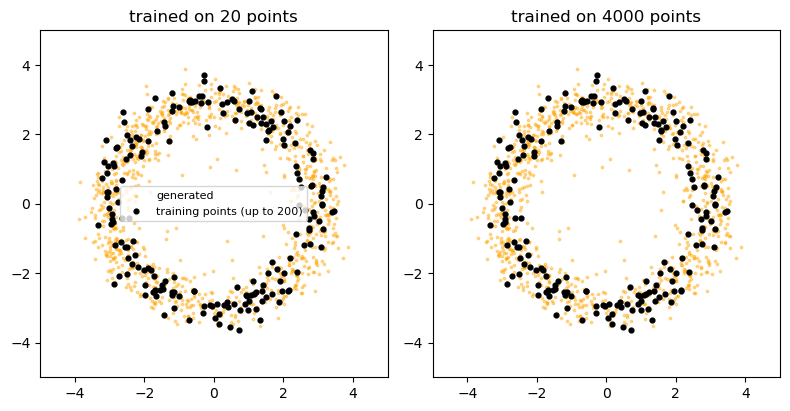

In [1]:
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt

def ring(n, seed):
    """n points on a ring of radius 3, with a little spread."""
    g = torch.Generator().manual_seed(seed)
    theta = torch.rand(n, generator=g) * 2 * np.pi
    r = 3 + 0.3 * torch.randn(n, generator=g)
    return torch.stack([r * torch.cos(theta), r * torch.sin(theta)], 1)

T = 100                                                   # noise steps
betas = torch.linspace(1e-4, 0.05, T); alphas = 1 - betas; abar = torch.cumprod(alphas, 0)

class Denoiser(nn.Module):
    """Predicts the noise that was added to x at step t."""
    def __init__(self, h=128):
        super().__init__()
        self.t = nn.Embedding(T, h)
        self.net = nn.Sequential(nn.Linear(2 + h, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU(), nn.Linear(h, 2))
    def forward(self, x, t):
        return self.net(torch.cat([x, self.t(t)], 1))

def train_and_sample(data, steps=3000, n_out=1000, seed=0):
    torch.manual_seed(seed); net = Denoiser(); opt = torch.optim.Adam(net.parameters(), 2e-3)
    for _ in range(steps):                                # learn to remove noise
        x0 = data[torch.randint(0, len(data), (256,))]
        t = torch.randint(0, T, (256,)); eps = torch.randn_like(x0)
        xt = abar[t, None].sqrt() * x0 + (1 - abar[t, None]).sqrt() * eps
        loss = F.mse_loss(net(xt, t), eps); opt.zero_grad(); loss.backward(); opt.step()
    x = torch.randn(n_out, 2)                             # start from pure noise ...
    with torch.no_grad():
        for t in reversed(range(T)):                      # ... and remove it step by step
            eps = net(x, torch.full((n_out,), t))
            x = (x - betas[t] / (1 - abar[t]).sqrt() * eps) / alphas[t].sqrt()
            if t > 0: x = x + betas[t].sqrt() * torch.randn_like(x)
    return x

results = {}
for n_train in [20, 4000]:
    data = ring(4000, seed=1)                             # FIX: this should be n_train training points
    gen = train_and_sample(data)
    to_train = torch.cdist(gen, data).min(1).values.median().item()
    perfect = torch.cdist(ring(1000, seed=3), data).min(1).values.median().item()
    on_ring = torch.cdist(gen, ring(4000, seed=2)).min(1).values.median().item()
    results[n_train] = (data, gen)
    print(f"trained on {n_train:4d} points: median distance to the nearest training point {to_train:.3f} "
          f"(perfect ring sampler {perfect:.3f}); to the ring itself {on_ring:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, (n, (data, gen)) in zip(axes, results.items()):
    ax.scatter(*gen.T, s=3, alpha=0.4, color="orange", label="generated")
    ax.scatter(*data[:200].T, s=12, color="k", label="training points (up to 200)")
    ax.set_title(f"trained on {n} points"); ax.set_aspect("equal"); ax.set_xlim(-5, 5); ax.set_ylim(-5, 5)
axes[0].legend(fontsize=8, loc="center"); plt.tight_layout(); plt.show()

**If you finish early.**

1. Is memorisation always bad? When would copying a known structure be exactly what you want from a
   structure predictor?
2. How would you build a test set that separates generalisation from memorisation for AlphaFold3's
   antibody complexes? (Session 8: homology partitioning.)
3. In protein design (RFdiffusion, ProteinMPNN), when do you want novelty, and when is a design
   close to a known, stable fold useful?

**Discussion point.** As it was, both models trained on the same 4000 points, so both looked
like the 4000-point model: generated points spread along the whole ring, about as close to the
training points as a perfect sampler (0.037 against 0.034). An experiment with this bug answers a
different question from the one it asks. The fix:

```python
data = ring(n_train, seed=1)
```

Trained on 20 points, the model still generates points *on the ring* (median 0.04 from it), but
they lie about twice as close to the 20 training points (0.28) as a perfect ring sampler would
(0.53): they bunch around the examples, with gaps between them. It has learned something of the
shape and memorised much of the examples. With 4000 points, nothing is left to memorise separately:
the examples *are* the ring.

This is the question behind AlphaFold3's antibody results: high accuracy near the training data
says little about new kinds of complexes, unless the test set is built to exclude them.